# Ablation-Studie (LGBM, schnell & vergleichbar)

**Ziel:** Herausfinden, welche Teile von `fs06` echte Information liefern, welche nur Rauschen sind und ob das Original-Dataset (inkl. Teacher) etwas bringt.

**Prinzip:** Immer genau *eine* Sache ausbauen, alles andere gleich lassen (gleiches Modell, gleiche Folds, gleicher Seed) und die OOF-AUC mit der Baseline vergleichen.

**Wichtig – deine Projektdateien bleiben unangetastet:**
- `src/*.py` werden nur importiert. Anpassungen (z. B. `ORIGINAL_FILE = None`) passieren *nur im Speicher* dieses Notebooks.
- Es wird eine **eigene** CV-Schleife benutzt – keine Checkpoints in `Models/saved_models`, kein Eintrag in `experiments.csv`.
- Es wird nur neu geschrieben nach `Results/ablation/` (Ergebnistabelle, damit ein Abbruch nicht alles verliert).

Ablauf: Setup → Einstellungen → Hilfsfunktionen → Rauschgrenze messen → alle Varianten → Tabelle & Plots → Kombination → Auswertung.

In [1]:
import os, sys, time, json, warnings
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")

# Projektwurzel finden (Ordner, der "src" enthaelt) – egal, wo das Notebook liegt
_p = Path.cwd().resolve()
for _cand in [_p, *_p.parents]:
    if (_cand / "src").is_dir():
        ROOT = _cand
        break
else:
    raise FileNotFoundError("Ordner 'src' nicht gefunden – Notebook im Projektordner starten.")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src import config as cfg
import src.data as data_mod
from src.data import load_data

print("Projektordner:", ROOT)

Projektordner: /home/cgd16/Desktop/Projekte/04 - Kaggle/01 - Playground Series - Season 6 Episode 10 - Predicting Airline Satisfaction


## Einstellungen
Die Lernrate ist hier absichtlich höher als in deiner Haupt-Config (schneller). Für den *Vergleich* der Varianten ist das egal, solange sie in allen Läufen gleich ist.

In [2]:
FEATURE_SET = "fs06"            # Baseline
ABL_SEED = 42                   # Seed (= Folds) fuer alle Varianten -> paarweise vergleichbar
NOISE_SEEDS = [42, 2026, 10]    # Baseline mit diesen Seeds -> Rauschgrenze
ABL_SPLITS = 5                  # Folds (weniger als 10 = schneller)

LGBM_OVERRIDE = dict(learning_rate=0.05, n_estimators=3000)   # nur fuers Tempo
EARLY_STOP = 100
MIN_EFFECT = 2e-5               # kleinster Effekt, den wir ueberhaupt ernst nehmen

RESUME = True                   # bereits berechnete Laeufe aus der CSV wiederverwenden
OUT_DIR = cfg.RESULTS_DIR / "ablation"
OUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUT_DIR / "ablation_results.csv"
IMPORTANCE_CSV = OUT_DIR / "baseline_importance.csv"

print("LGBM-Parameter (aus config, mit Override):")
print({**cfg.PARAMS["lgbm"], **LGBM_OVERRIDE})

LGBM-Parameter (aus config, mit Override):
{'learning_rate': 0.05, 'num_leaves': 128, 'max_depth': 10, 'min_child_samples': 100, 'subsample': 0.85, 'subsample_freq': 1, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0, 'device': 'cuda', 'n_estimators': 3000}


## Hilfsfunktionen: Daten laden (mit temporären Umbiegungen) & Feature-Gruppen
`get_data(key)` ruft dein unverändertes `load_data` auf, biegt dafür aber **im Speicher** kurz um:
- `base`: wie in deiner Config (mit Original, Original in den Statistiken)
- `no_orig`: `ORIGINAL_FILE = None` (kein Original, kein Teacher, Statistiken nur auf Train+Test)
- `orig_sep`: Original bekommt eigene Statistiken (`orig_in_stats=False`)

In [3]:
_DATA_CACHE = {}

@contextmanager
def _patched(orig_file, orig_in_stats):
    old_file, old_fn = cfg.ORIGINAL_FILE, data_mod.add_features_joint
    def wrapper(train, test, orig, feature_set, orig_in_stats=True):
        return old_fn(train, test, orig, feature_set, orig_in_stats=_patched.ois)
    _patched.ois = orig_in_stats
    try:
        cfg.ORIGINAL_FILE = orig_file
        data_mod.add_features_joint = wrapper
        yield
    finally:
        cfg.ORIGINAL_FILE = old_file
        data_mod.add_features_joint = old_fn

def get_data(key):
    if key in _DATA_CACHE:
        return _DATA_CACHE[key]
    print(f"[Daten] lade '{key}' ...")
    if key == "base":
        with _patched(cfg.ORIGINAL_FILE, True):
            d = load_data(FEATURE_SET)
    elif key == "no_orig":
        with _patched(None, True):
            d = load_data(FEATURE_SET)
    elif key == "orig_sep":
        with _patched(cfg.ORIGINAL_FILE, False):
            d = load_data(FEATURE_SET)
    else:
        raise ValueError(key)
    _DATA_CACHE[key] = d
    return d

def free_data(key):
    if key != "base":
        _DATA_CACHE.pop(key, None)

# --- Feature-Gruppen (Namen nach dem Umbenennen: Leerzeichen -> _) ---
GROUP_SPEC = {
    "teacher": dict(names=["original_teacher_logit"]),
    "route": dict(prefix=["Route_"]),
    "exp_rating": dict(prefix=["Exp_Rating_", "Diff_Exp_Rating_"]),
    "interact_group": dict(names=[
        "Wifi_x_Boarding", "Total_Delay", "Delay_Ratio",
        "Group_Dist_Mean", "Group_Dist_Std", "Diff_From_Group_Dist_Mean", "Class_DepDelay_Mean"]),
    "combos": dict(names=[
        "Class_TypeTravel", "Class_CustomerType", "Class_TypeTravel_CustomerType", "Class_Wifi"]),
}

def cols_of(columns, group):
    spec = GROUP_SPEC[group]
    out = [c for c in columns if c in spec.get("names", [])]
    out += [c for c in columns if any(c.startswith(p) for p in spec.get("prefix", []))]
    return sorted(set(out))

_RAW_RATINGS = [c.replace(" ", "_") for c in cfg.ORDINAL_FEATURES]
def group_of(col):
    for g in GROUP_SPEC:
        if col in cols_of([col], g):
            return g
    if col in _RAW_RATINGS:
        return "raw_ratings"
    if col.startswith("Rating_") or col in ("N_Zero", "N_Low", "N_High"):
        return "rating_agg"
    return "rest (Rohdaten, Delay, Distance ...)"

## Eigene CV-Schleife (gleiche Logik wie `src/cv.py`, aber ohne Checkpoints)
Wie in deiner `cv.py`: In-Fold-Target-Encoding auf `Route_ID` (falls vorhanden), Original-Zeilen werden ans Training angehängt (inkl. Encoding aus den Train-Fold-Labels). Early Stopping auf dem Validierungs-Fold, nur AUC als Metrik.

In [4]:
def te_map(k_train, y_train, k_valid, smooth=20.0):
    prior = y_train.mean()
    stats = pd.DataFrame({"k": k_train, "y": y_train}).groupby("k")["y"].agg(["sum", "count"])
    mapping = (stats["sum"] + prior * smooth) / (stats["count"] + smooth)
    return pd.Series(k_valid).map(mapping).fillna(prior).values.astype(np.float32)


def run_cv_lgbm(data, drop_groups=(), use_orig_rows=True, use_te=True, seed=ABL_SEED, n_splits=ABL_SPLITS):
    drop = sorted({c for g in drop_groups for c in cols_of(data.X.columns, g)})
    X, y = data.X.drop(columns=drop), data.y
    Xo = yo = None
    if data.X_orig is not None and use_orig_rows:
        Xo, yo = data.X_orig.drop(columns=drop), data.y_orig
    has_te = use_te and ("Route_ID" in X.columns)

    oof = np.zeros(len(X)); fold_aucs, best_its = [], []
    imp = pd.Series(0.0, index=list(X.columns) + (["Route_Target_Enc"] if has_te else []))

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, va in skf.split(X, y):
        X_tr, y_tr = X.iloc[tr].copy(), y.iloc[tr]
        X_va, y_va = X.iloc[va].copy(), y.iloc[va]

        if has_te:
            inner = np.zeros(len(X_tr), dtype=np.float32)
            for itr, iva in StratifiedKFold(5, shuffle=True, random_state=seed).split(X_tr, y_tr):
                inner[iva] = te_map(X_tr["Route_ID"].iloc[itr], y_tr.iloc[itr], X_tr["Route_ID"].iloc[iva])
            X_tr["Route_Target_Enc"] = inner
            X_va["Route_Target_Enc"] = te_map(X_tr["Route_ID"], y_tr, X_va["Route_ID"])

        if Xo is not None:
            Xo_f = Xo.copy()
            if has_te:
                Xo_f["Route_Target_Enc"] = te_map(X_tr["Route_ID"], y_tr, Xo_f["Route_ID"])
            X_tr = pd.concat([X_tr, Xo_f], ignore_index=True)
            y_tr = pd.concat([y_tr, yo], ignore_index=True)

        params = {**cfg.PARAMS["lgbm"], **LGBM_OVERRIDE}
        model = lgb.LGBMClassifier(**params, metric="auc", random_state=seed, verbosity=-1, n_jobs=-1)
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="auc",
                  callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
        p = model.predict_proba(X_va)[:, 1]
        oof[va] = p
        fold_aucs.append(roc_auc_score(y_va, p))
        best_its.append(model.best_iteration_)
        g = pd.Series(model.booster_.feature_importance("gain"), index=model.booster_.feature_name())
        imp = imp.add(g, fill_value=0.0)

    return dict(auc=roc_auc_score(y, oof), fold_aucs=fold_aucs, n_features=X.shape[1] + int(has_te),
                mean_best_iter=float(np.mean(best_its)), importance=imp / imp.sum())

## Varianten
| Name | Was wird geändert? |
|---|---|
| `v0_baseline` | `fs06` unverändert |
| `v1_no_original` | Kein Original (weder Zeilen noch Teacher noch in den Statistiken) |
| `v2_orig_rows_no_teacher` | Original-Zeilen ja, Teacher-Logit raus |
| `v3_teacher_no_orig_rows` | Teacher-Logit ja, Original-Zeilen nicht im Training |
| `v4_no_route_feats` | Alle `Route_*`-Features raus (inkl. `Route_ID` und Target-Encoding) |
| `v4b_no_route_target_enc` | Nur das In-Fold-Target-Encoding raus, `Route_*` bleiben |
| `v5_no_exp_rating` | `Exp_Rating_*` und `Diff_Exp_Rating_*` raus |
| `v6_no_interact_group` | Interaktionen & Group-Aggregate raus |
| `v7_no_combos` | String-Kombinationen (`Class_TypeTravel...`) raus |
| `v8_orig_separate_stats` | Original bekommt eigene Statistiken statt gemeinsamer |

Eigene Varianten kannst du einfach im Dict `VARIANTS` ergänzen.

In [5]:
DEFAULTS = dict(data_key="base", drop=[], use_orig_rows=True, use_te=True, desc="")

VARIANTS = {
    "v0_baseline":             dict(desc="fs06 unveraendert"),
    "v1_no_original":          dict(data_key="no_orig", desc="kein Original (Zeilen, Teacher, Statistik)"),
    "v2_orig_rows_no_teacher": dict(drop=["teacher"], desc="Original-Zeilen ja, Teacher raus"),
    "v3_teacher_no_orig_rows": dict(use_orig_rows=False, desc="Teacher ja, Original-Zeilen raus"),
    "v4_no_route_feats":       dict(drop=["route"], desc="alle Route_* raus"),
    "v4b_no_route_target_enc": dict(use_te=False, desc="nur Route-Target-Encoding raus"),
    "v5_no_exp_rating":        dict(drop=["exp_rating"], desc="Exp_/Diff_Exp_Rating raus"),
    "v6_no_interact_group":    dict(drop=["interact_group"], desc="Interaktionen + Group-Aggs raus"),
    "v7_no_combos":            dict(drop=["combos"], desc="String-Kombinationen raus"),
    "v8_orig_separate_stats":  dict(data_key="orig_sep", desc="Original mit eigenen Statistiken"),
}

results = {}   # (variant, seed) -> dict

def save_results():
    rows = []
    for (name, seed), r in results.items():
        rows.append(dict(variant=name, seed=seed, auc=r["auc"], fold_aucs=json.dumps(r["fold_aucs"]),
                         n_features=r["n_features"], mean_best_iter=r["mean_best_iter"],
                         time=r.get("time", np.nan), desc=r.get("desc", "")))
    pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)

def load_results():
    if not (RESUME and RESULTS_CSV.exists()):
        return
    df = pd.read_csv(RESULTS_CSV)
    for _, row in df.iterrows():
        results[(row["variant"], int(row["seed"]))] = dict(
            auc=row["auc"], fold_aucs=json.loads(row["fold_aucs"]), n_features=int(row["n_features"]),
            mean_best_iter=row["mean_best_iter"], time=row["time"], desc=row["desc"], importance=None)
    print(f"{len(results)} Ergebnisse aus {RESULTS_CSV.name} geladen (RESUME=True).")

def run_variant(name, spec=None, seed=ABL_SEED):
    spec = {**DEFAULTS, **(spec if spec is not None else VARIANTS[name])}
    key = (name, seed)
    if key in results:
        return results[key]
    t0 = time.time()
    d = get_data(spec["data_key"])
    r = run_cv_lgbm(d, spec["drop"], spec["use_orig_rows"], spec["use_te"], seed)
    r.update(time=time.time() - t0, desc=spec["desc"])
    results[key] = r
    free_data(spec["data_key"])
    save_results()
    if name == "v0_baseline" and seed == ABL_SEED:
        r["importance"].sort_values(ascending=False).to_csv(IMPORTANCE_CSV, header=["gain_share"])
    print(f"{name:28s} seed={seed:<5d} AUC={r['auc']:.6f}  Features={r['n_features']:3d}  "
          f"best_it~{r['mean_best_iter']:.0f}  {r['time']:.0f}s")
    return r

load_results()

## 1) Rauschgrenze messen
Die Baseline läuft mit mehreren Seeds. Die Streuung der OOF-AUC ist ein grober Anhaltspunkt, ab welcher Differenz ein Effekt überhaupt interpretierbar ist.

In [6]:
for s in NOISE_SEEDS:
    run_variant("v0_baseline", seed=s)

noise_aucs = [results[("v0_baseline", s)]["auc"] for s in NOISE_SEEDS]
NOISE = float(np.std(noise_aucs, ddof=1)) if len(noise_aucs) > 1 else 0.0
THR = max(2 * NOISE, MIN_EFFECT)

print(f"\nBaseline-AUCs: {[round(a, 6) for a in noise_aucs]}")
print(f"Rauschen (Std ueber Seeds): {NOISE:.6f}  ->  Schwelle fuer 'echten' Effekt: {THR:.6f}")
print("Hinweis: Varianten werden mit demselben Seed/denselben Folds verglichen (paarweise) - "
      "das Rauschen dort ist eher kleiner als diese Schaetzung.")

[Daten] lade 'base' ...
Originaldatensatz geladen: (129880, 22)
train (699635, 23) | test (299844, 22) | sample_submission (299844, 2)
Trainiere Original-Data Teacher Modell...
Teacher OOF-AUC auf Original: 0.994973
Original-Data Teacher Feature erfolgreich generiert!
Hinweis: Test hat keine fehlenden Arrival-Delay-Werte -> 'Arrival_Delay_Missing' entfernt
Feature-Set fs06: 91 Features (kategorisch: 9)
v0_baseline                  seed=42    AUC=0.960253  Features= 92  best_it~253  81s
v0_baseline                  seed=2026  AUC=0.960309  Features= 92  best_it~306  76s
v0_baseline                  seed=10    AUC=0.960262  Features= 92  best_it~246  59s

Baseline-AUCs: [0.960253, 0.960309, 0.960262]
Rauschen (Std ueber Seeds): 0.000030  ->  Schwelle fuer 'echten' Effekt: 0.000060
Hinweis: Varianten werden mit demselben Seed/denselben Folds verglichen (paarweise) - das Rauschen dort ist eher kleiner als diese Schaetzung.


## 2) Alle Varianten laufen lassen
Das dauert je nach Rechner eine Weile; nach jeder Variante wird in die CSV gespeichert (bei Abbruch einfach die Zelle erneut starten).

In [7]:
for name in VARIANTS:
    run_variant(name)

[Daten] lade 'no_orig' ...
train (699635, 23) | test (299844, 22) | sample_submission (299844, 2)
Hinweis: Test hat keine fehlenden Arrival-Delay-Werte -> 'Arrival_Delay_Missing' entfernt
Feature-Set fs06: 90 Features (kategorisch: 9)
v1_no_original               seed=42    AUC=0.958624  Features= 91  best_it~204  55s
v2_orig_rows_no_teacher      seed=42    AUC=0.960343  Features= 91  best_it~285  63s
v3_teacher_no_orig_rows      seed=42    AUC=0.960761  Features= 92  best_it~225  53s
v4_no_route_feats            seed=42    AUC=0.958726  Features= 71  best_it~305  57s
v4b_no_route_target_enc      seed=42    AUC=0.960128  Features= 91  best_it~261  58s
v5_no_exp_rating             seed=42    AUC=0.960161  Features= 66  best_it~244  55s
v6_no_interact_group         seed=42    AUC=0.960252  Features= 85  best_it~255  57s
v7_no_combos                 seed=42    AUC=0.960229  Features= 88  best_it~265  58s
[Daten] lade 'orig_sep' ...
Originaldatensatz geladen: (129880, 22)
train (699635, 23

## 3) Ergebnistabelle

In [8]:
def build_table():
    base = results[("v0_baseline", ABL_SEED)]
    rows = []
    for (name, seed), r in results.items():
        if seed != ABL_SEED:
            continue
        delta = r["auc"] - base["auc"]
        fa, fb = np.array(r["fold_aucs"]), np.array(base["fold_aucs"])
        better = int((fa > fb).sum()) if name != "v0_baseline" else np.nan
        if name == "v0_baseline":
            code_ = "baseline"
        elif delta < -THR:
            code_ = "keep"          # Ausbau schadet -> Komponente traegt Information
        elif delta > THR:
            code_ = "harmful"       # Ausbau hilft -> Komponente schadet
        else:
            code_ = "neutral"       # kein Unterschied -> eher entfernen
        rows.append(dict(variant=name, auc=r["auc"], delta=delta, better_folds=better,
                         n_folds=len(fa), n_features=r["n_features"], verdict_code=code_,
                         desc=r.get("desc", "")))
    t = pd.DataFrame(rows).set_index("variant")
    order = [v for v in VARIANTS if v in t.index] + [v for v in t.index if v not in VARIANTS]
    return t.loc[order]

LABEL = {"baseline": "Referenz",
         "keep": "behalten (Ausbau schadet)",
         "neutral": "egal -> eher entfernen",
         "harmful": "entfernen (schadet)"}

table = build_table()
show = table.assign(urteil=table["verdict_code"].map(LABEL)).drop(columns="verdict_code")
try:
    display(show.style.format({"auc": "{:.6f}", "delta": "{:+.6f}"})
            .background_gradient(subset=["delta"], cmap="RdYlGn"))
except Exception:
    display(show.round(6))
print(f"Schwelle fuer echten Effekt: +/- {THR:.6f}")

,auc,delta,better_folds,n_folds,n_features,desc,urteil
variant,,,,,,,
v0_baseline,0.960253,0.000000,NaN,5,92,fs06 unveraendert,Referenz
v1_no_original,0.958624,-0.001629,4.0,5,91,"kein Original (Zeilen, Teacher, Statistik)",behalten (Ausbau schadet)
v2_orig_rows_no_teacher,0.960343,0.000090,5.0,5,91,"Original-Zeilen ja, Teacher raus",entfernen (schadet)
v3_teacher_no_orig_rows,0.960761,0.000509,5.0,5,92,"Teacher ja, Original-Zeilen raus",entfernen (schadet)
v4_no_route_feats,0.958726,-0.001527,0.0,5,71,alle Route_* raus,behalten (Ausbau schadet)
v4b_no_route_target_enc,0.960128,-0.000125,1.0,5,91,nur Route-Target-Encoding raus,behalten (Ausbau schadet)
v5_no_exp_rating,0.960161,-0.000092,0.0,5,66,Exp_/Diff_Exp_Rating raus,behalten (Ausbau schadet)
v6_no_interact_group,0.960252,-0.000000,3.0,5,85,Interaktionen + Group-Aggs raus,egal -> eher entfernen
v7_no_combos,0.960229,-0.000023,2.0,5,88,String-Kombinationen raus,egal -> eher entfernen


Schwelle fuer echten Effekt: +/- 0.000060


## 4) Δ-AUC zur Baseline
Balken nach links = Variante ist schlechter als die Baseline (Komponente war nützlich). Der graue Streifen ist die Rauschgrenze.

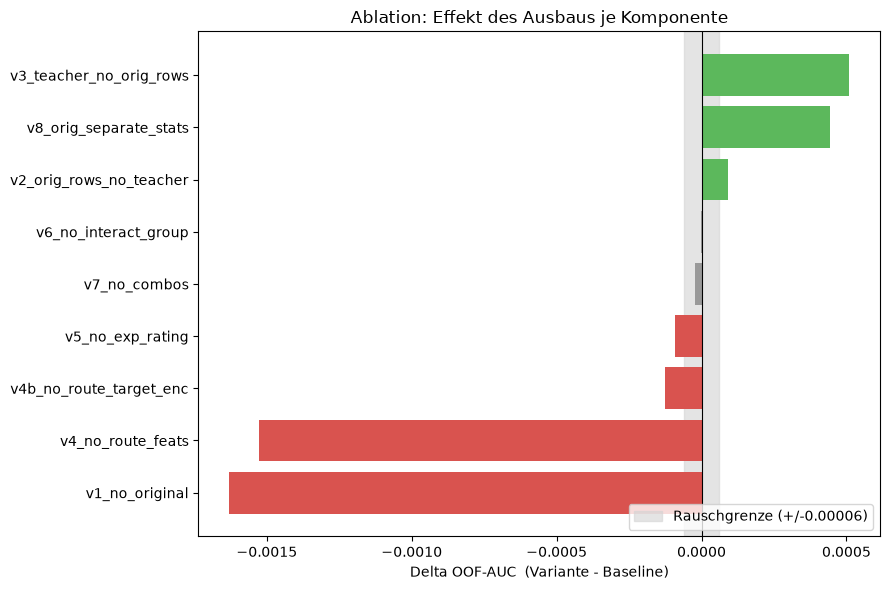

In [9]:
t = table[table.index != "v0_baseline"].sort_values("delta")
colors = t["verdict_code"].map({"keep": "#d9534f", "neutral": "#999999", "harmful": "#5cb85c"})
fig, ax = plt.subplots(figsize=(9, 0.5 * len(t) + 1.5))
ax.axvspan(-THR, THR, color="lightgray", alpha=0.6, label=f"Rauschgrenze (+/-{THR:.5f})")
ax.barh(t.index, t["delta"], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Delta OOF-AUC  (Variante - Baseline)")
ax.set_title("Ablation: Effekt des Ausbaus je Komponente")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5) Fold-weise Konsistenz
Gleiche Farbe über (fast) alle Folds = belastbares Ergebnis. Gemischte Farben = eher Zufall. Werte in 1e-4 AUC.

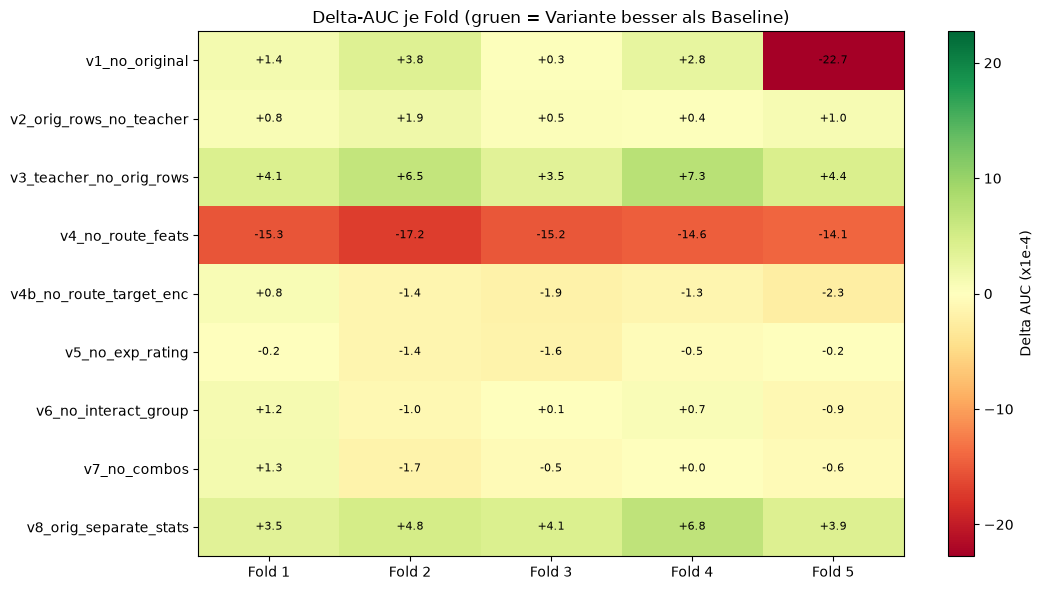

In [10]:
base_f = np.array(results[("v0_baseline", ABL_SEED)]["fold_aucs"])
names = [n for n in table.index if n != "v0_baseline"]
M = np.array([(np.array(results[(n, ABL_SEED)]["fold_aucs"]) - base_f) * 1e4 for n in names])
v = max(abs(M).max(), 0.5)

fig, ax = plt.subplots(figsize=(1.2 * M.shape[1] + 5, 0.5 * len(names) + 1.5))
im = ax.imshow(M, cmap="RdYlGn", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([f"Fold {i+1}" for i in range(M.shape[1])])
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:+.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Delta AUC (x1e-4)")
ax.set_title("Delta-AUC je Fold (gruen = Variante besser als Baseline)")
plt.tight_layout(); plt.show()

## 6) Feature-Wichtigkeit der Baseline (Gain)
Zeigt, woher das Modell sein Signal bezieht – hilft beim Entscheiden, was noch aufgeräumt werden kann.

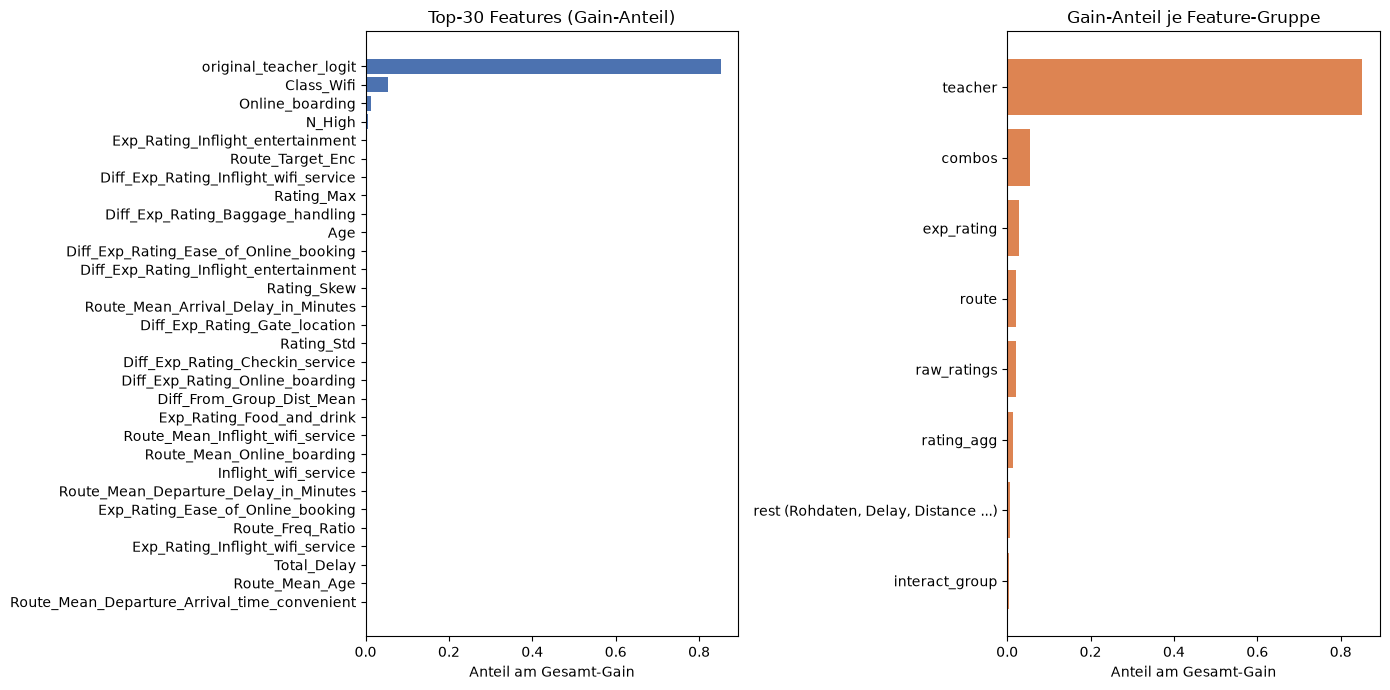

,n_features,gain_share
teacher,1,0.8516
combos,4,0.0550
exp_rating,26,0.0284
route,21,0.0222
raw_ratings,13,0.0201
rating_agg,9,0.0131
"rest (Rohdaten, Delay, Distance ...)",11,0.0058
interact_group,7,0.0039


In [11]:
imp = results[("v0_baseline", ABL_SEED)].get("importance")
if imp is None and IMPORTANCE_CSV.exists():
    imp = pd.read_csv(IMPORTANCE_CSV, index_col=0)["gain_share"]
if imp is None:
    print("Keine Wichtigkeiten vorhanden - 'v0_baseline' einmal ohne RESUME neu rechnen.")
else:
    imp = imp.sort_values(ascending=False)
    grp = imp.groupby(imp.index.map(group_of)).sum().sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    top = imp.head(30)[::-1]
    axes[0].barh(top.index, top.values, color="#4c72b0")
    axes[0].set_title("Top-30 Features (Gain-Anteil)")
    axes[1].barh(grp.index, grp.values, color="#dd8452")
    axes[1].set_title("Gain-Anteil je Feature-Gruppe")
    for a in axes: a.set_xlabel("Anteil am Gesamt-Gain")
    plt.tight_layout(); plt.show()

    n_feat = imp.groupby(imp.index.map(group_of)).size()
    display(pd.DataFrame({"n_features": n_feat, "gain_share": grp}).sort_values("gain_share", ascending=False).round(4))

## 7) Kombination aller „überflüssigen“ Komponenten
Effekte addieren sich nicht automatisch: Was einzeln egal ist, kann zusammen schaden (die Gruppen ersetzen sich gegenseitig). Deshalb werden hier alle **Feature-Drop-Varianten mit Urteil „egal“ oder „schadet“** gemeinsam entfernt und gegen die Baseline getestet.
(Varianten mit Original-Änderungen – v1, v3, v8 – werden nicht automatisch kombiniert, die bewertest du selbst anhand der Tabelle.)

In [12]:
table = build_table()
cand = [n for n in table.index
        if n in VARIANTS and n != "v0_baseline"
        and VARIANTS[n].get("data_key", "base") == "base"
        and VARIANTS[n].get("use_orig_rows", True)
        and table.loc[n, "verdict_code"] in ("neutral", "harmful")]

print("Kandidaten fuer die Kombination:", cand)
if cand:
    drop_union = sorted({g for n in cand for g in VARIANTS[n].get("drop", [])})
    use_te = all(VARIANTS[n].get("use_te", True) for n in cand)
    combo_name = "combo_" + "+".join(drop_union or ["keep"]) + ("" if use_te else "+noTE")
    combo_spec = dict(drop=drop_union, use_te=use_te,
                      desc=f"Kombination: drop={drop_union}, use_te={use_te}")
    r = run_variant(combo_name, combo_spec)
    base = results[("v0_baseline", ABL_SEED)]
    fa, fb = np.array(r["fold_aucs"]), np.array(base["fold_aucs"])
    print(f"\nBaseline : {base['auc']:.6f}  ({base['n_features']} Features)")
    print(f"Kombi    : {r['auc']:.6f}  ({r['n_features']} Features)")
    print(f"Delta    : {r['auc'] - base['auc']:+.6f}  | bessere Folds: {(fa > fb).sum()}/{len(fa)}")
    print("-> Kombi >= Baseline - Schwelle: schlankeres Set uebernehmen." if r["auc"] - base["auc"] >= -THR
          else "-> Kombi schlechter: Komponenten ersetzen sich gegenseitig, nur einzeln entfernen.")
else:
    print("Keine Komponente ist 'egal' oder 'schaedlich' - Feature-Set bleibt, wie es ist.")

Kandidaten fuer die Kombination: ['v2_orig_rows_no_teacher', 'v6_no_interact_group', 'v7_no_combos']
combo_combos+interact_group+teacher seed=42    AUC=0.960392  Features= 80  best_it~284  60s

Baseline : 0.960253  (92 Features)
Kombi    : 0.960392  (80 Features)
Delta    : +0.000139  | bessere Folds: 5/5
-> Kombi >= Baseline - Schwelle: schlankeres Set uebernehmen.


## 8) Eigene Varianten (optional)
Beliebige Kombination testen, z. B. alles entfernen, was einzeln nichts brachte, plus ohne Teacher:
```python
run_variant("custom_a", dict(drop=["route", "exp_rating", "teacher"], use_te=False, desc="schlankes Set"))
build_table()
```
Verfügbare Gruppen: `teacher`, `route`, `exp_rating`, `interact_group`, `combos`.

In [13]:
# run_variant("custom_a", dict(drop=["route", "exp_rating"], use_te=False, desc="schlankes Set"))
# build_table()

## Auswertung – wie lese ich das?
- **Δ deutlich negativ** (über der Rauschgrenze, in fast allen Folds): Komponente trägt Information → behalten.
- **Δ ≈ 0:** Komponente ist überflüssig → entfernen (weniger Features, weniger Rauschen, schnellere Läufe).
- **Δ positiv:** Komponente schadet → entfernen.
- **`v1`/`v2`/`v3`** beantworten die Original-Frage: Hilft das Original als Zeilen, als Teacher oder gar nicht? Falls es gar nichts bringt, kannst du dir weitere Arbeit am Teacher (z. B. `init_score`, mehrere Teacher) sparen.
- **Danach:** Mit dem schlankeren Feature-Set als *neues* `FEATURE_SET` (z. B. `fs07`) die vollen Läufe starten (3 Modelle, 8 Seeds, 10 Folds). Wichtig: neuer Name → keine alten Checkpoints.

**Grenzen:** Ein Ergebnis mit LGBM gilt nicht automatisch für XGB/CatBoost, und die Baseline-Streuung ist nur eine grobe Schätzung. Kleine Effekte (unter ca. 0.0001) sollten nur dann übernommen werden, wenn sie über viele Folds konsistent sind.